# Perbandingan Metode Clustering — Dataset Training Selada

Dataset: `Dataset/lettuce_dataset_training.csv` — **sudah merupakan 70% dari dataset asli**,
sehingga TIDAK ada pembagian proporsi data lagi di notebook ini.

**Struktur:** dataset dimuat dan dipreprocessing satu kali (Langkah 1–3) menghasilkan satu
matriks fitur `X`; seluruh model (Langkah 4) dan tiap bagian evaluasi (Bagian A–E) memproses
`X` secara langsung.

# Langkah 1: Setup & Import

In [ ]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, pairwise_distances)
try:
    from sklearn.cluster import HDBSCAN  # sklearn >= 1.3
except ImportError:
    HDBSCAN = None

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
K = 4              # jumlah klaster tetap untuk metode partisi (hasil elbow)
MIN_SAMPLES = 10   # ambang minimum anggota klaster / parameter DBSCAN & HDBSCAN
EPS = 0.64         # eps DBSCAN (dari k-distance graph)
K_RANGE = range(2, 11)

# Langkah 2: Load Dataset

In [ ]:
# File training tidak punya header, jadi nama kolom didefinisikan manual
COLUMNS = ['Plant_ID', 'Date', 'Temperature (°C)', 'Humidity (%)',
           'TDS Value (ppm)', 'pH Level', 'Growth Days',
           'Temperature (F)', 'Humidity']

# encoding latin1 karena ada simbol derajat (°) pada penamaan kolom asli
df = pd.read_csv('Dataset/lettuce_dataset_training.csv', header=None,
                 names=COLUMNS, encoding='latin1')

print(f"Total data training: {df.shape[0]} baris, {df.shape[1]} kolom")
print(f"Missing value total: {int(df.isna().sum().sum())}")
print(f"Duplikat baris: {df.duplicated().sum()}")
df.head()

Total data training: 2213 baris, 9 kolom
Missing value total: 0
Duplikat baris: 0


,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
0,22,8/3/2023,33.4,70,620,6.2,1,92.12,0.70
1,22,8/4/2023,33.5,63,800,6.5,2,92.30,0.63
2,22,8/5/2023,33.4,50,602,6.0,3,92.12,0.50
3,22,8/6/2023,33.4,50,721,6.0,4,92.12,0.50
4,22,8/7/2023,33.4,65,571,6.3,5,92.12,0.65


# Langkah 3: Preprocessing

Dataset training sudah menjadi representasi 70% dari dataset asli, maka tidak dilakukan
sampling/splitting lagi. Hasil preprocessing adalah **satu matriks `X`** yang dipakai
bersama oleh semua metode clustering.

In [ ]:
# Buang kolom redundan: Temperature (F) = salinan °C, Humidity = salinan Humidity (%)
df_clean = df.drop(columns=['Temperature (F)', 'Humidity'])

features = ['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level', 'Growth Days']

# Standardisasi sekali pada SELURUH data training -> satu ruang fitur untuk semua metode
scaler = StandardScaler()
X = scaler.fit_transform(df_clean[features])
df_scaled = pd.DataFrame(X, columns=features, index=df_clean.index)

print(f"Data terproses untuk semua model: {X.shape[0]} baris x {X.shape[1]} fitur")

Data terproses untuk semua model: 2213 baris x 5 fitur


# Langkah 4: Definisi Model & Fungsi Evaluasi

In [ ]:
class CustomKMeans:
    """K-Means dari nol dengan jarak Euclidean (centroid = rata-rata)."""
    def __init__(self, n_clusters=3, max_iters=100, metric='euclidean'):
        self.n_clusters = n_clusters
        self.max_iters = max_iters
        self.metric = metric
        self.centroids = None
        self.labels = None
        self.inertia_ = 0

    def fit(self, X):
        np.random.seed(RANDOM_STATE)
        random_idx = np.random.choice(len(X), self.n_clusters, replace=False)
        self.centroids = X[random_idx]

        for _ in range(self.max_iters):
            distances = cdist(X, self.centroids, metric=self.metric)
            self.labels = np.argmin(distances, axis=1)

            new_centroids = np.zeros((self.n_clusters, X.shape[1]))
            for i in range(self.n_clusters):
                cluster_data = X[self.labels == i]
                if len(cluster_data) > 0:
                    new_centroids[i] = np.mean(cluster_data, axis=0)
                else:
                    new_centroids[i] = self.centroids[i]

            if np.allclose(self.centroids, new_centroids):
                break
            self.centroids = new_centroids

        final_dist = cdist(X, self.centroids, metric=self.metric)
        self.inertia_ = np.sum(np.min(final_dist, axis=1) ** 2)
        return self

In [ ]:
class CustomKMedians:
    """K-Medians dari nol dengan jarak Manhattan/cityblock (centroid = median)."""
    def __init__(self, n_clusters=3, max_iters=100, metric='cityblock'):
        self.n_clusters = n_clusters
        self.max_iters = max_iters
        self.metric = metric
        self.centroids = None
        self.labels = None
        self.inertia_ = 0

    def fit(self, X):
        np.random.seed(RANDOM_STATE)
        random_idx = np.random.choice(len(X), self.n_clusters, replace=False)
        self.centroids = X[random_idx]

        for _ in range(self.max_iters):
            distances = cdist(X, self.centroids, metric=self.metric)
            self.labels = np.argmin(distances, axis=1)

            new_centroids = np.zeros((self.n_clusters, X.shape[1]))
            for i in range(self.n_clusters):
                cluster_data = X[self.labels == i]
                if len(cluster_data) > 0:
                    new_centroids[i] = np.median(cluster_data, axis=0)
                else:
                    new_centroids[i] = self.centroids[i]

            if np.allclose(self.centroids, new_centroids):
                break
            self.centroids = new_centroids

        final_dist = cdist(X, self.centroids, metric=self.metric)
        self.inertia_ = np.sum(np.min(final_dist, axis=1))  # error absolut
        return self

In [ ]:
class KMeansCosine:
    """Spherical K-Means: assignment pakai Cosine Distance, centroid = rata-rata ter-normalisasi L2."""
    def __init__(self, n_clusters=3, max_iter=300, tol=1e-4, random_state=RANDOM_STATE):
        self.n_clusters, self.max_iter, self.tol, self.random_state = n_clusters, max_iter, tol, random_state

    def _dist(self, X, C):
        return pairwise_distances(X, C, metric='cosine')

    def fit(self, X):
        Xn, n = normalize(X), len(X)  # normalisasi L2 bagian dari algoritma, bukan preprocessing

        # Inisialisasi centroid ala k-means++ (jarak cosine)
        rng = np.random.RandomState(self.random_state)
        C = [Xn[rng.randint(n)]]
        for _ in range(self.n_clusters - 1):
            d = self._dist(Xn, np.array(C)).min(axis=1) ** 2
            C.append(Xn[rng.choice(n, p=np.ones(n) / n if d.sum() == 0 else d / d.sum())])
        self.centroids = normalize(np.array(C))

        rng = np.random.RandomState(self.random_state)  # dipakai jika ada klaster kosong
        for self.n_iter_ in range(1, self.max_iter + 1):
            labels = self._dist(Xn, self.centroids).argmin(axis=1)
            new_c = np.array([normalize(Xn[labels == k].mean(axis=0, keepdims=True))[0] if (labels == k).any()
                              else Xn[rng.randint(n)] for k in range(self.n_clusters)])
            shift = np.linalg.norm(new_c - self.centroids)
            self.centroids, self.labels_ = new_c, labels
            if shift <= self.tol:
                break

        self.inertia_ = self._dist(Xn, self.centroids)[np.arange(n), self.labels_].sum()
        return self

In [ ]:
def get_labels(model):
    """Label hasil fit, konsisten untuk model custom (.labels) maupun sklearn (.labels_)."""
    return model.labels_ if hasattr(model, 'labels_') else model.labels

def evaluate(X, labels):
    """Metrik seragam (Euclidean pada data StandardScaler).
    Titik noise DBSCAN (-1) diabaikan; butuh minimal 2 klaster, jika tidak -> NaN."""
    m = labels != -1
    if len(set(labels[m])) < 2:
        return [np.nan] * 3
    return [silhouette_score(X[m], labels[m]),
            davies_bouldin_score(X[m], labels[m]),
            calinski_harabasz_score(X[m], labels[m])]

def run_method(model, X):
    """Jalankan satu metode pada matriks X, kembalikan (label, waktu detik)."""
    t0 = time.perf_counter()
    model.fit(X)
    return np.asarray(get_labels(model)), time.perf_counter() - t0

def find_elbow_point(k_vals, inertias):
    """Titik siku = jarak terjauh dari garis lurus (k_awal -> k_akhir)."""
    pts = np.column_stack([k_vals, inertias]).astype(float)
    u = (pts[-1] - pts[0]) / np.linalg.norm(pts[-1] - pts[0])
    v = pts - pts[0]
    return int(k_vals[np.argmax(np.linalg.norm(v - np.outer(v @ u, u), axis=1))])

def scatter_pca(labels, cmap, title, noise_marker=False, X_=None):
    """Scatter PCA 2D satu kali (tanpa grid split)."""
    Z = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X if X_ is None else X_)
    plt.figure(figsize=(8, 6))
    plt.scatter(Z[:, 0], Z[:, 1], c=labels, cmap=cmap, s=25, alpha=0.7)
    plt.colorbar(label='Cluster')
    plt.title(title); plt.xlabel('PCA 1'); plt.ylabel('PCA 2')
    plt.show()

# Bagian A: Euclidean Distance (K-Means Custom)

k hasil elbow = 6 | k yang digunakan = 4

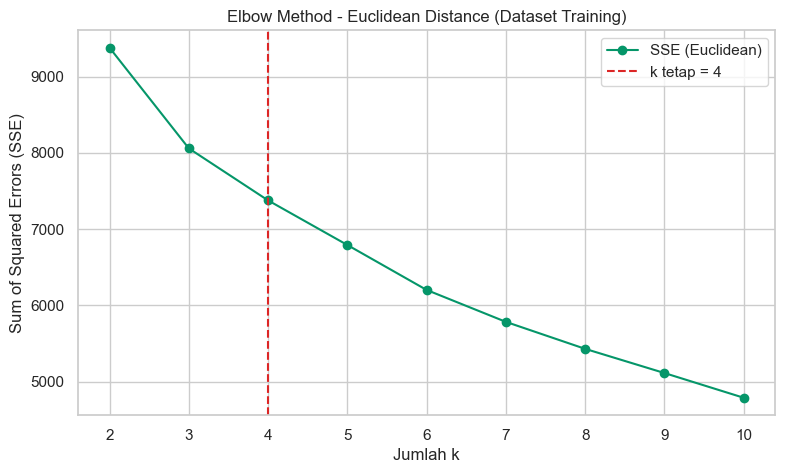

In [ ]:
sse = [CustomKMeans(n_clusters=k, metric='euclidean').fit(X).inertia_ for k in K_RANGE]
elbow_k = find_elbow_point(list(K_RANGE), sse)
print(f"k hasil elbow = {elbow_k} | k yang digunakan = {K}")

plt.figure(figsize=(9, 5))
plt.plot(K_RANGE, sse, marker='o', color='#059669', label='SSE (Euclidean)')
plt.axvline(K, color='#DC2626', linestyle='--', label=f'k tetap = {K}')
plt.xlabel('Jumlah k'); plt.ylabel('Sum of Squared Errors (SSE)')
plt.title('Elbow Method - Euclidean Distance (Dataset Training)')
plt.xticks(K_RANGE); plt.legend(); plt.show()

In [ ]:
labels_euclid, t = run_method(CustomKMeans(n_clusters=K, metric='euclidean'), X)
sil, db, ch = evaluate(X, labels_euclid)
euclid_df = pd.DataFrame([{'Model': 'K-Means (Euclidean)', 'Jumlah Sampel': len(X), 'Cluster': K,
                            'Silhouette Score': round(sil, 4), 'Davies-Bouldin': round(db, 4),
                            'Calinski-Harabasz': round(ch, 2), 'Waktu Eksekusi (s)': round(t, 5)}])
euclid_df

,Model,Jumlah Sampel,Cluster,Silhouette Score,Davies-Bouldin,Calinski-Harabasz,Waktu Eksekusi (s)
0,K-Means (Euclidean),2213,4,0.1477,1.6851,368.39,0.01173


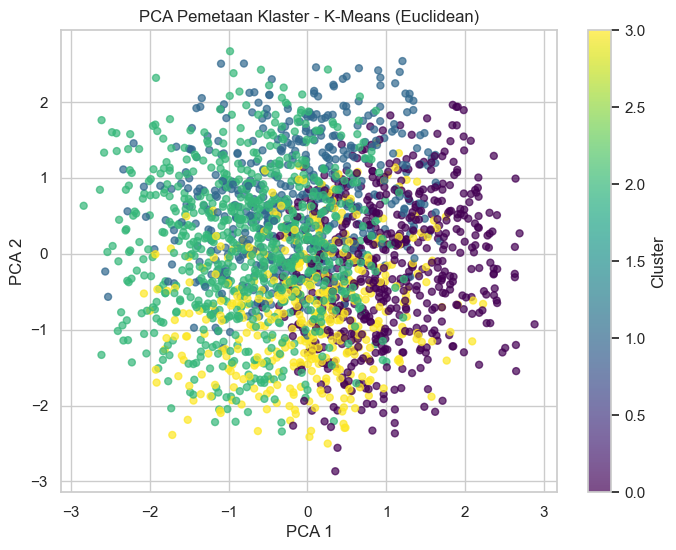

In [ ]:
scatter_pca(labels_euclid, 'viridis', 'PCA Pemetaan Klaster - K-Means (Euclidean)')

# Bagian B: Manhattan Distance (K-Medians Custom)

k hasil elbow = 6 | k yang digunakan = 4


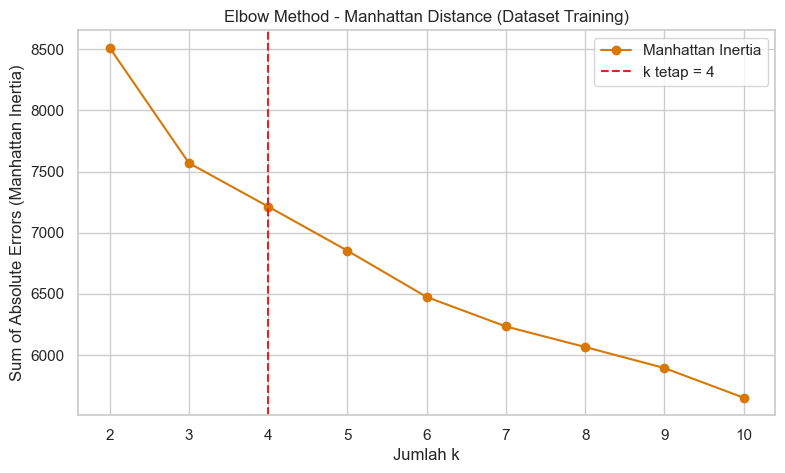

In [ ]:
sia = [CustomKMedians(n_clusters=k, metric='cityblock').fit(X).inertia_ for k in K_RANGE]
elbow_k = find_elbow_point(list(K_RANGE), sia)
print(f"k hasil elbow = {elbow_k} | k yang digunakan = {K}")

plt.figure(figsize=(9, 5))
plt.plot(K_RANGE, sia, marker='o', color='#D97706', label='Manhattan Inertia')
plt.axvline(K, color='#DC2626', linestyle='--', label=f'k tetap = {K}')
plt.xlabel('Jumlah k'); plt.ylabel('Sum of Absolute Errors (Manhattan Inertia)')
plt.title('Elbow Method - Manhattan Distance (Dataset Training)')
plt.xticks(K_RANGE); plt.legend(); plt.show()

In [ ]:
labels_manhattan, t = run_method(CustomKMedians(n_clusters=K, metric='cityblock'), X)
sil, db, ch = evaluate(X, labels_manhattan)  # metrik Euclidean agar seragam antar metode
manhattan_df = pd.DataFrame([{'Model': 'K-Medians (Manhattan)', 'Jumlah Sampel': len(X), 'Cluster': K,
                               'Silhouette Score': round(sil, 4), 'Davies-Bouldin': round(db, 4),
                               'Calinski-Harabasz': round(ch, 2), 'Waktu Eksekusi (s)': round(t, 5)}])
manhattan_df

,Model,Jumlah Sampel,Cluster,Silhouette Score,Davies-Bouldin,Calinski-Harabasz,Waktu Eksekusi (s)
0,K-Medians (Manhattan),2213,4,0.1253,1.8379,325.52,0.01112


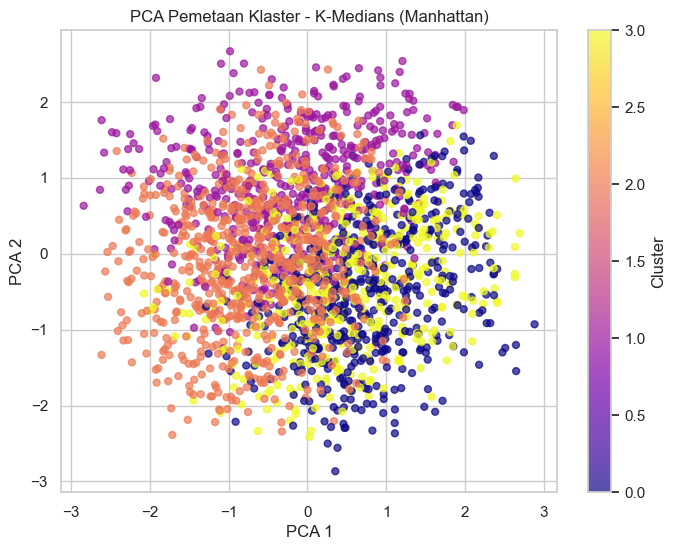

In [ ]:
scatter_pca(labels_manhattan, 'plasma', 'PCA Pemetaan Klaster - K-Medians (Manhattan)')

# Bagian C: Cosine Similarity (Spherical K-Means Custom)

k hasil elbow = 5 | k yang digunakan = 4


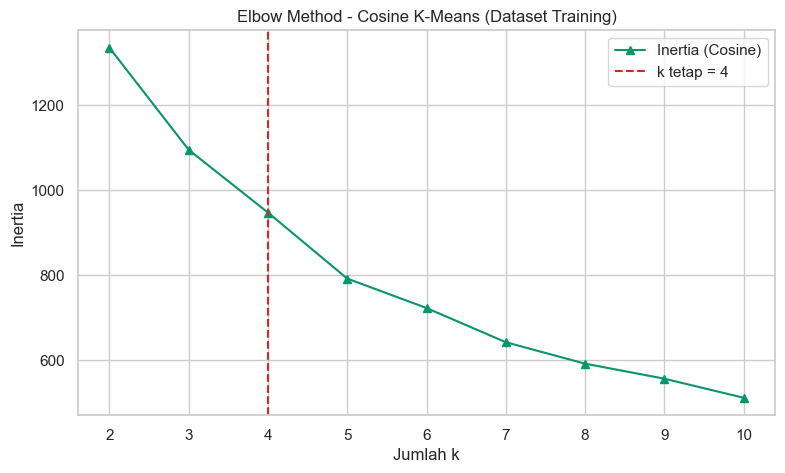

In [ ]:
sse_cos = [KMeansCosine(n_clusters=k, max_iter=200).fit(X).inertia_ for k in K_RANGE]
elbow_k = find_elbow_point(list(K_RANGE), sse_cos)
print(f"k hasil elbow = {elbow_k} | k yang digunakan = {K}")

plt.figure(figsize=(9, 5))
plt.plot(K_RANGE, sse_cos, marker='^', color='#059669', label='Inertia (Cosine)')
plt.axvline(K, color='#DC2626', linestyle='--', label=f'k tetap = {K}')
plt.xlabel('Jumlah k'); plt.ylabel('Inertia')
plt.title('Elbow Method - Cosine K-Means (Dataset Training)')
plt.xticks(K_RANGE); plt.legend(); plt.show()

In [ ]:
labels_cosine, t = run_method(KMeansCosine(n_clusters=K), X)
sil, db, ch = evaluate(X, labels_cosine)
cosine_df = pd.DataFrame([{'Model': 'K-Means (Cosine)', 'Jumlah Sampel': len(X), 'Cluster': K,
                            'Silhouette Score': round(sil, 4), 'Davies-Bouldin': round(db, 4),
                            'Calinski-Harabasz': round(ch, 2), 'Waktu Eksekusi (s)': round(t, 5)}])
cosine_df

,Model,Jumlah Sampel,Cluster,Silhouette Score,Davies-Bouldin,Calinski-Harabasz,Waktu Eksekusi (s)
0,K-Means (Cosine),2213,4,0.1441,1.8678,340.68,0.0747


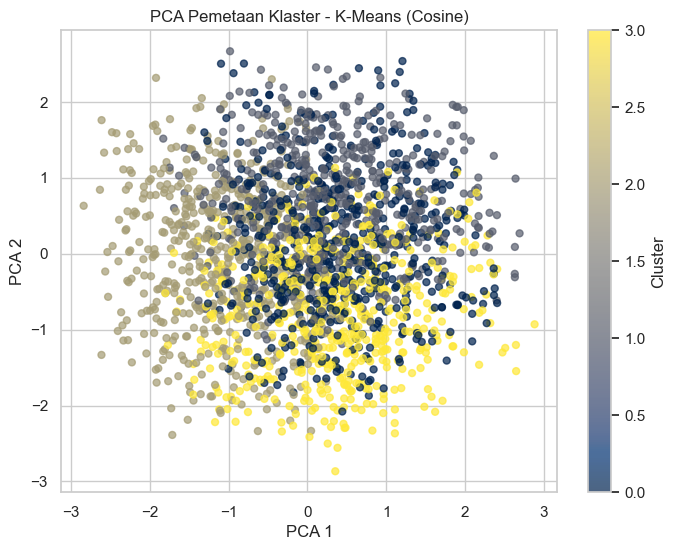

In [ ]:
scatter_pca(labels_cosine, 'cividis', 'PCA Pemetaan Klaster - K-Means (Cosine)')

# Bagian D: DBSCAN — Core, Border, dan Noise

DBSCAN dijalankan langsung pada matriks `X` hasil Langkah 3 (tanpa split).

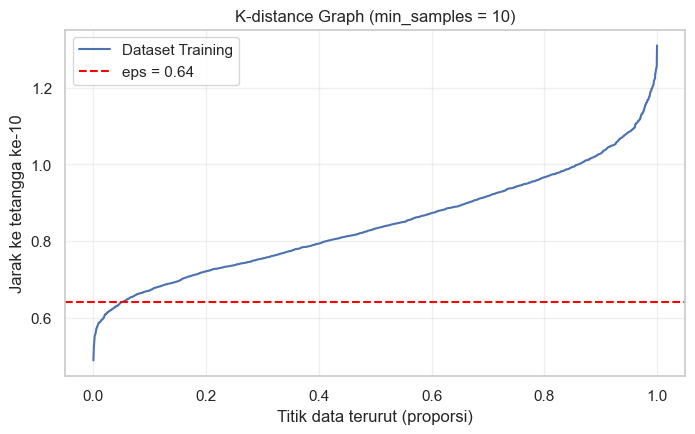

In [ ]:
# K-distance graph untuk rujukan nilai EPS
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X)
kd = np.sort(nn.kneighbors(X)[0][:, -1])

plt.figure(figsize=(8, 4.5))
plt.plot(np.arange(len(kd)) / len(kd), kd, label='Dataset Training')
plt.axhline(EPS, color='red', ls='--', label=f'eps = {EPS}')
plt.xlabel('Titik data terurut (proporsi)')
plt.ylabel(f'Jarak ke tetangga ke-{MIN_SAMPLES}')
plt.title(f'K-distance Graph (min_samples = {MIN_SAMPLES})')
plt.legend(); plt.grid(alpha=.3); plt.show()

In [ ]:
t0 = time.perf_counter()
db_model = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(X)
t_db = time.perf_counter() - t0
labels_db = db_model.labels_

core_mask = np.zeros(len(labels_db), dtype=bool)
core_mask[db_model.core_sample_indices_] = True
types_db = np.where(core_mask, 'Core', np.where(labels_db != -1, 'Border', 'Noise'))

sil, dbi, ch = evaluate(X, labels_db)
df_dbscan = pd.DataFrame([{'Model': 'DBSCAN', 'Jumlah Sampel': len(X), 'eps': EPS, 'min_samples': MIN_SAMPLES,
                           'Jumlah Cluster': len(set(labels_db) - {-1}),
                           'Core Sample': int((types_db == 'Core').sum()),
                           'Border Instance': int((types_db == 'Border').sum()),
                           'Noise': int((types_db == 'Noise').sum()),
                           '% Noise': round(100 * (types_db == 'Noise').sum() / len(X), 2),
                           'Silhouette Score': round(sil, 4), 'Davies-Bouldin': round(dbi, 4),
                           'Calinski-Harabasz': round(ch, 2), 'Waktu Eksekusi (s)': round(t_db, 5)}])
display(df_dbscan)

,Model,Jumlah Sampel,eps,min_samples,Jumlah Cluster,Core Sample,Border Instance,Noise,% Noise,Silhouette Score,Davies-Bouldin,Calinski-Harabasz,Waktu Eksekusi (s)
0,DBSCAN,2213,0.64,10,25,108,383,1722,77.81,0.255,1.014,99.48,0.03633


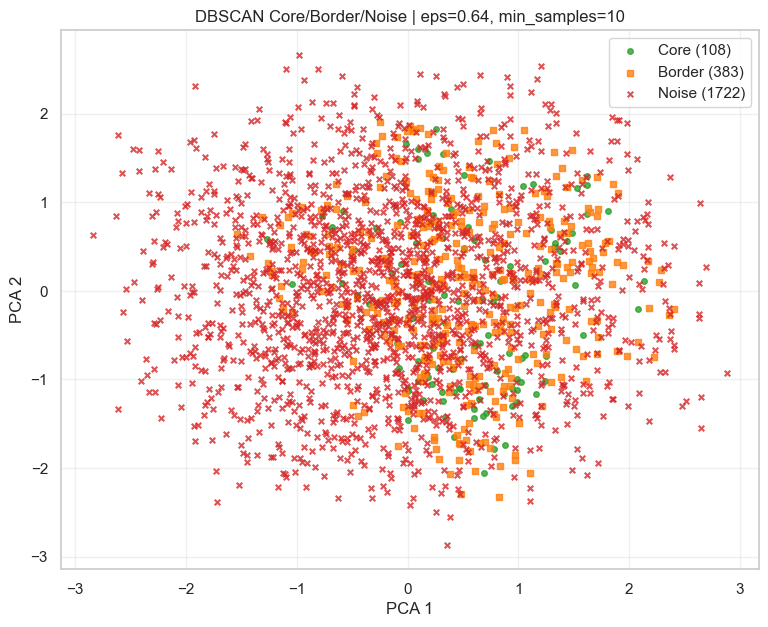

In [ ]:
# Visualisasi tipe titik (Core/Border/Noise) pada proyeksi PCA
Z = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)
plt.figure(figsize=(9, 7))
style = {'Core': ('#2ca02c', 'o'), 'Border': ('#ff7f0e', 's'), 'Noise': ('#d62728', 'x')}
for tname in ['Core', 'Border', 'Noise']:
    m = types_db == tname
    plt.scatter(Z[m, 0], Z[m, 1], s=16, color=style[tname][0], marker=style[tname][1],
                alpha=0.8, label=f'{tname} ({m.sum()})')
plt.title(f'DBSCAN Core/Border/Noise | eps={EPS}, min_samples={MIN_SAMPLES}')
plt.xlabel('PCA 1'); plt.ylabel('PCA 2'); plt.legend(); plt.grid(alpha=.3); plt.show()

In [ ]:
# Contoh baris Border Instance (dataset mentah)
idx_border = df_scaled.index[types_db == 'Border'][:5]
display(df_clean.loc[idx_border, features])

,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days
0,33.4,70,620,6.2,1
4,33.4,65,571,6.3,5
18,30.2,55,678,6.0,19
19,30.5,52,534,6.2,20
21,31.3,51,542,6.3,22


# Bagian E: Perbandingan Final Semua Metode

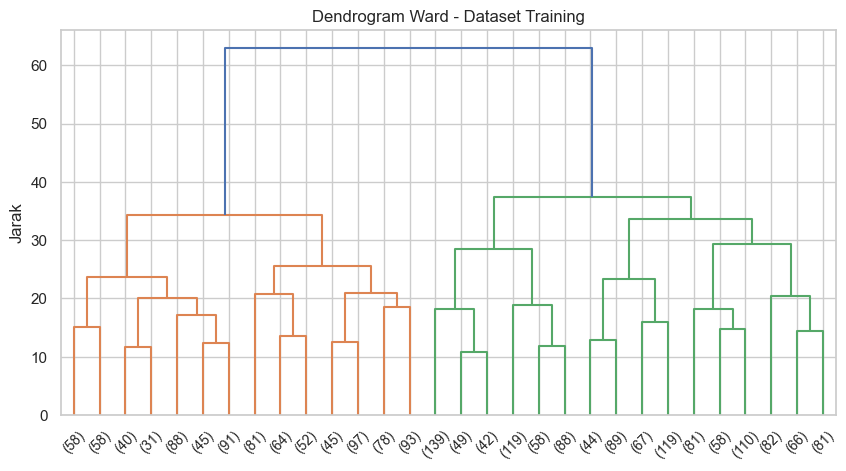

In [ ]:
plt.figure(figsize=(10, 5))
dendrogram(linkage(X, method='ward'), truncate_mode='lastp', p=30)
plt.title('Dendrogram Ward - Dataset Training')
plt.ylabel('Jarak'); plt.show()

## Tabel Gabungan: Semua Metode pada Dataset Training

In [ ]:
METHODS = {
    "K-Means (Euclidean)": lambda: CustomKMeans(n_clusters=K, metric='euclidean'),
    "K-Medians (Manhattan)": lambda: CustomKMedians(n_clusters=K, metric='cityblock'),
    "K-Means (Cosine)": lambda: KMeansCosine(n_clusters=K),
    "Hierarchical (Ward)": lambda: AgglomerativeClustering(n_clusters=K, linkage='ward'),
    "DBSCAN": lambda: DBSCAN(eps=EPS, min_samples=MIN_SAMPLES),
}
if HDBSCAN is not None:
    METHODS["HDBSCAN"] = lambda: HDBSCAN(min_cluster_size=MIN_SAMPLES, min_samples=MIN_SAMPLES)

rows, final_labels = [], {}
for mname, make in METHODS.items():
    labels, t = run_method(make(), X)
    final_labels[mname] = labels
    sil, db, ch = evaluate(X, labels)
    rows.append({'Metode': mname, 'Jumlah Sampel': len(X),
                 'Cluster': K if mname not in ('DBSCAN', 'HDBSCAN') else '-',
                 'Noise': int((labels == -1).sum()),
                 'Silhouette Score': round(sil, 4), 'Davies-Bouldin': round(db, 4),
                 'Calinski-Harabasz': round(ch, 2), 'Waktu Eksekusi (s)': round(t, 5)})

final_df = pd.DataFrame(rows)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 20)
display(final_df)

,Metode,Jumlah Sampel,Cluster,Noise,Silhouette Score,Davies-Bouldin,Calinski-Harabasz,Waktu Eksekusi (s)
0,K-Means (Euclidean),2213,4,0,0.1477,1.6851,368.39,0.00925
1,K-Medians (Manhattan),2213,4,0,0.1253,1.8379,325.52,0.00722
2,K-Means (Cosine),2213,4,0,0.1441,1.8678,340.68,0.06632
3,Hierarchical (Ward),2213,4,0,0.1261,2.3085,308.44,0.09537
4,DBSCAN,2213,-,1722,0.2550,1.0140,99.48,0.02128
5,HDBSCAN,2213,-,517,0.1958,1.9334,354.08,0.08696


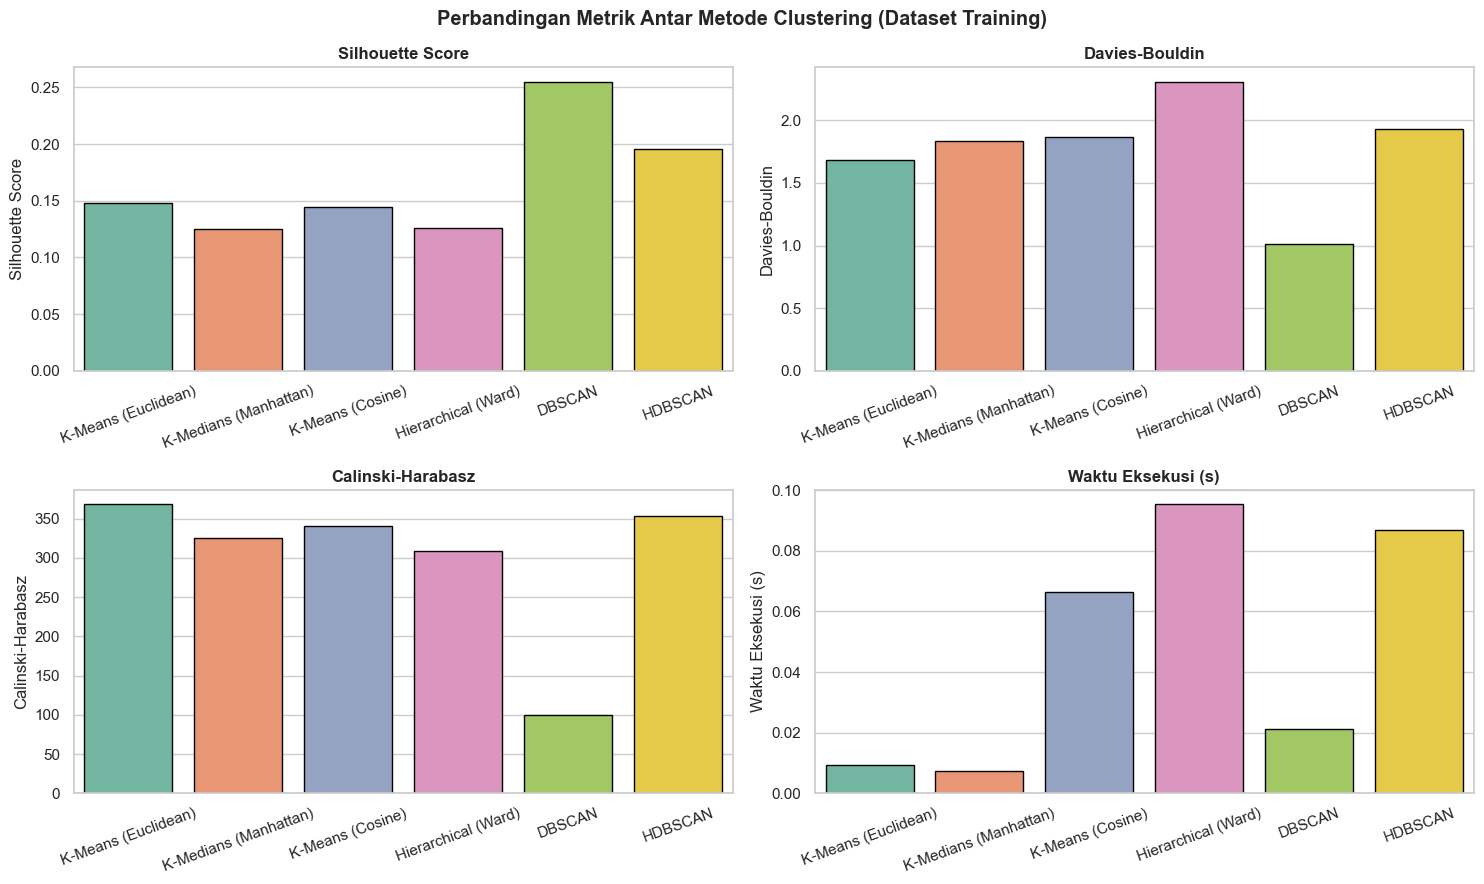

In [ ]:
metrics = ['Silhouette Score', 'Davies-Bouldin', 'Calinski-Harabasz', 'Waktu Eksekusi (s)']
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.ravel(), metrics):
    sns.barplot(data=final_df, x='Metode', y=col, ax=ax, palette='Set2', edgecolor='black')
    ax.set_title(col, fontweight='bold'); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
plt.suptitle('Perbandingan Metrik Antar Metode Clustering (Dataset Training)', fontweight='bold')
plt.tight_layout(); plt.show()

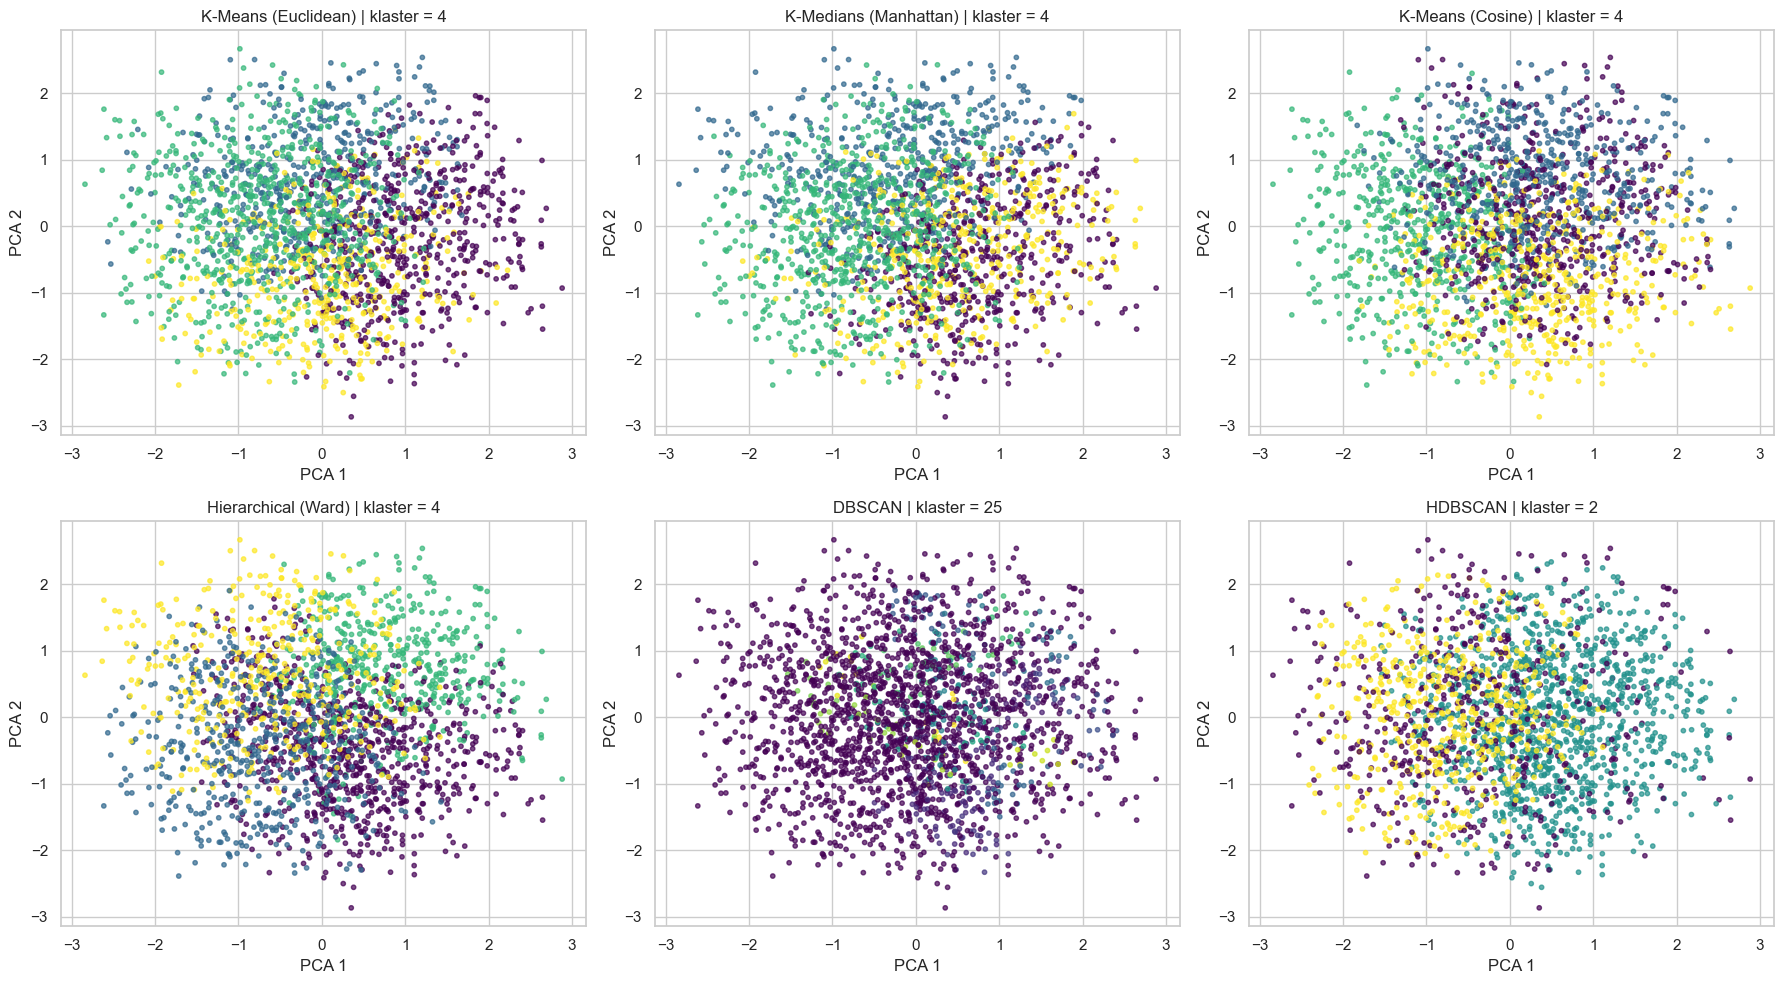

In [ ]:
# Visualisasi PCA semua metode (proyeksi sama untuk perbandingan adil)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
Z = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)
for ax, mname in zip(axes.ravel(), METHODS):
    labels = final_labels[mname]
    ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap='viridis', s=10, alpha=0.7)
    ax.set_title(f'{mname} | klaster = {len(set(labels) - {-1})}')
    ax.set_xlabel('PCA 1'); ax.set_ylabel('PCA 2')
plt.tight_layout(); plt.show()